# U-Chrom im: Z-projection quick test

This notebook tests the first `uchrom.im` Z-projection API with TIFF data under `F:\\project\\Caolab\\U-C-p\\UC\\test_data`.

It covers:
- whole-stack projection
- projection with a specified z range
- saving `.npy` and `.png` outputs
- directory batch projection


In [ ]:
from skimage import io as skio
from uchrom.im import z_project, z_project_dir
import matplotlib.pyplot as plt
import numpy as np

d:\Miniconda3\envs\uchrom\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [29]:
stack = skio.imread(str(tif_path)).squeeze()
print("input stack shape:", stack.shape)
print("input stack dtype:", stack.dtype)

if stack.ndim != 3:
    raise ValueError(f"Expected a 3D stack, got shape={stack.shape}")

zmax_demo = min(10, stack.shape[0])
print("demo z range: [0,", zmax_demo, ")")

input stack shape: (70, 1024, 1024)
input stack dtype: uint16
demo z range: [0, 10 )


## 1. Whole-stack projection

In [ ]:
z_project_dir('F:/project/Caolab/U-C-p/UC/test_data/raw/', zmin=1, zmax=70, method="mip")

In [ ]:
tif_path = 'F:/project/Caolab/U-C-p/UC/test_data/raw/scan_001_DAPI_005_ROI_converted_decon_ch00.tif'
sum_dapi = z_project(tif_path, zmin=1, zmax=70, method="sum")
mip_dapi = z_project(tif_path, zmin=1, zmax=70, method="mip", out_name="mip_dapi")

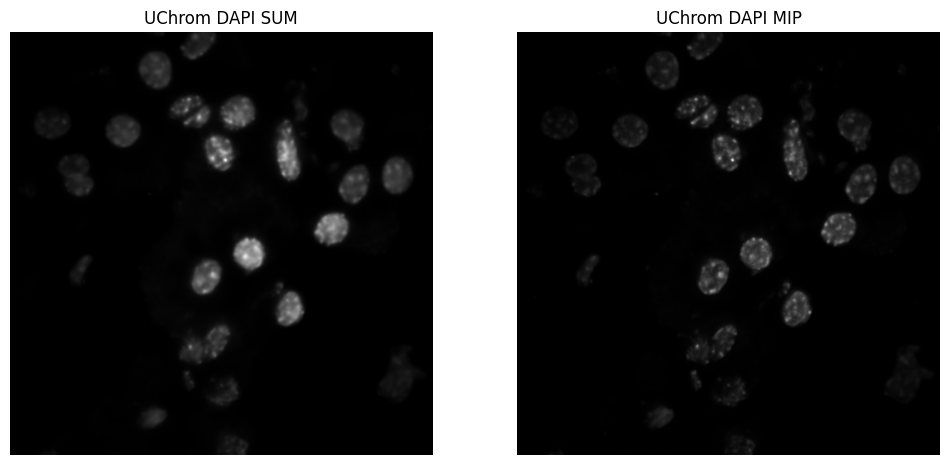

In [17]:
x = np.load(r"F:/project/Caolab/U-C-p/UC/test_data/project/data/scan_001_DAPI_005_ROI_converted_decon_ch00_2d.npy")

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(x, cmap="gray")
plt.title("UChrom DAPI SUM")
plt.axis("off")

y = np.load(r"F:/project/Caolab/U-C-p/UC/test_data/project/data/mip_dapi.npy")
plt.subplot(1, 2, 2)
plt.imshow(y, cmap="gray")
plt.title("UChrom DAPI MIP")
plt.axis("off")

plt.show()

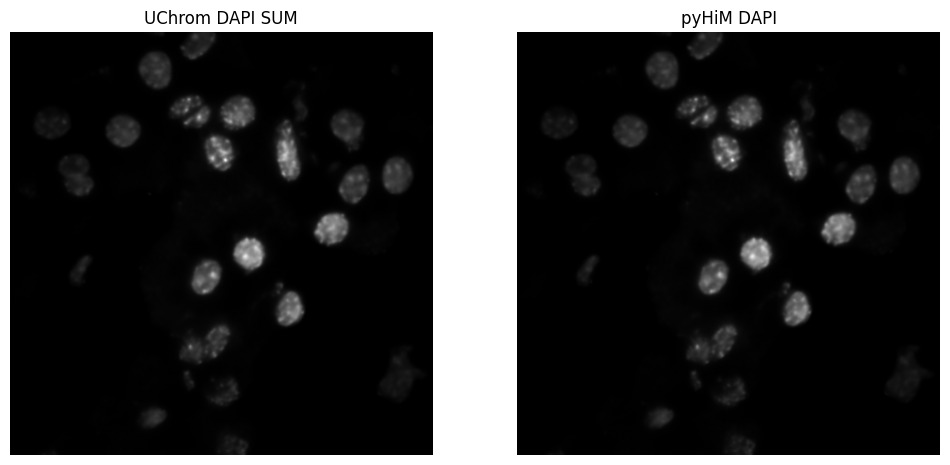

In [15]:
x = np.load(r"F:/project/Caolab/U-C-p/UC/test_data/project/data/scan_001_DAPI_005_ROI_converted_decon_ch00_2d.npy")

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(x, cmap="gray")
plt.title("UChrom DAPI SUM")
plt.axis("off")

y = np.load(r"F:/project/Caolab/U-C-p/pyHiM/test/test_dataset/project/data/scan_001_DAPI_005_ROI_converted_decon_ch00_2d.npy")
plt.subplot(1, 2, 2)
plt.imshow(y, cmap="gray")
plt.title("pyHiM DAPI")
plt.axis("off")

plt.show()


In [9]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

uchrom_npy = Path(r"F:/project/Caolab/U-C-p/UC/test_data/project/data/scan_001_DAPI_005_ROI_converted_decon_ch00_2d.npy")
pyhim_npy = Path(r"F:/project/Caolab/U-C-p/pyHiM/test/test_dataset/project/data/scan_001_DAPI_005_ROI_converted_decon_ch00_2d.npy")

a = np.load(uchrom_npy)
b = np.load(pyhim_npy)

print("uchrom:", a.shape, a.dtype, a.min(), a.max())
print("pyHiM :", b.shape, b.dtype, b.min(), b.max())

print("exact equal:", np.array_equal(a, b))

uchrom: (1024, 1024) float64 0.0 1012092.0
pyHiM : (1024, 1024) float64 0.0 1012092.0
exact equal: True


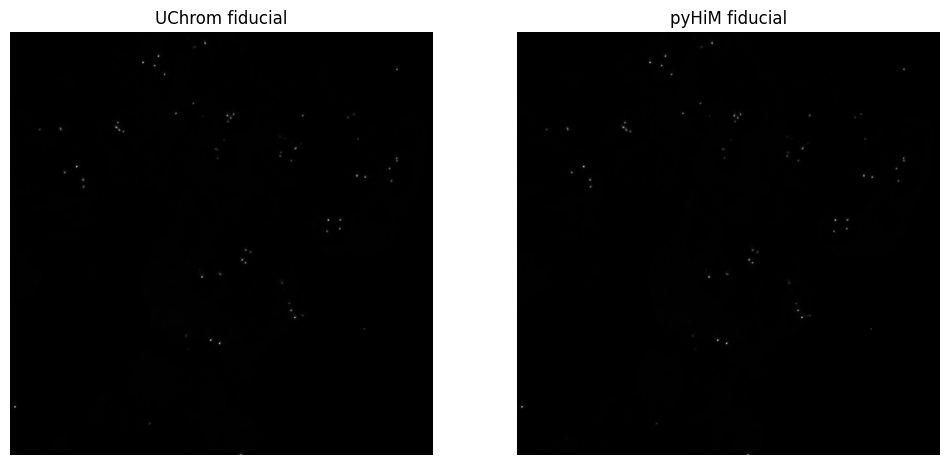

In [11]:
x = np.load(r"F:/project/Caolab/U-C-p/UC/test_data/project/data/scan_001_DAPI_005_ROI_converted_decon_ch01_2d.npy")

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(x, cmap="gray")
plt.title("UChrom fiducial")
plt.axis("off")

y = np.load(r"F:/project/Caolab/U-C-p/pyHiM/test/test_dataset/project/data/scan_001_DAPI_005_ROI_converted_decon_ch01_2d.npy")
plt.subplot(1, 2, 2)
plt.imshow(x, cmap="gray")
plt.title("pyHiM fiducial")
plt.axis("off")

plt.show()

## 2. Projection with a specified z range

This only uses slices `[0, zmax_demo)`.

In [ ]:
sum_range = z_project(tif_path, method="sum", zmin=0, zmax=zmax_demo, save=False)
print("range projection shape:", sum_range.shape)
print("range projection dtype:", sum_range.dtype)
print("range projection min/max:", sum_range.min(), sum_range.max())

plt.figure(figsize=(6, 6))
plt.imshow(sum_range, cmap="gray")
plt.title(f"SUM from z range [0, {zmax_demo})")
plt.axis("off")
plt.show()


## 3. Save `.npy` and `.png`

This writes outputs to `U-Chrom/project/data/` and `U-Chrom/project/preview/`.

In [ ]:
out_root = repo_root / "project"
_ = z_project(tif_path, method="mip", save=True, out_dir=out_root)

npy_path = out_root / "data" / f"{tif_path.stem}_2d.npy"
png_path = out_root / "preview" / f"{tif_path.stem}_2d.png"

print("saved npy:", npy_path)
print("saved png:", png_path)
print("npy exists:", npy_path.exists())
print("png exists:", png_path.exists())


## 4. Batch project a directory

This processes all `.tif` and `.tiff` files directly under the test data directory.

In [ ]:
batch_out_root = repo_root / "project_batch"
records = z_project_dir(test_data_dir, method="mip", out_dir=batch_out_root)

print("processed files:", len(records))
records[0]
